In [12]:
from pathlib import Path
import pandas as pd
import sqlite3

In [13]:
current_path = Path.cwd()
project_path = None

for path in [current_path, *current_path.parents]:
    if (path / "data" / "processed" / "retail_cleaned.csv").exists():
        project_path = path
        break

In [14]:
if project_path is None:
    print("Cleaned CSV file nahi mili!")
    print("Current working directory:", current_path)
else:
    print("Project folder:", project_path)

Project folder: c:\Users\pantv\OneDrive\Desktop\Projects\Retail Intelligence


In [15]:
csv_path = project_path / "data" / "processed" / "retail_cleaned.csv"
df = pd.read_csv(csv_path)
print("Dataset loaded:", df.shape)

Dataset loaded: (0, 9)


In [16]:
db_path = project_path / "data" / "processed" / "retail.db"
conn = sqlite3.connect(db_path)
df.to_sql("retail", conn, if_exists="replace", index=False)

0

In [17]:
tables = pd.read_sql_query(
"SELECT name FROM sqlite_master WHERE type='table';",
conn)
print("\nDatabase location:", db_path)
print("\nAvailable tables:")
print(tables)


Database location: c:\Users\pantv\OneDrive\Desktop\Projects\Retail Intelligence\data\processed\retail.db

Available tables:
     name
0  reatil
1  retail


In [18]:
query = """
SELECT ROUND(SUM(Revenue), 2) AS total_revenue
FROM retail;
"""
result = pd.read_sql_query(query, conn)
print("\nTotal Revenue:")
print(result)


Total Revenue:
  total_revenue
0          None


In [19]:
query = """
SELECT
Description,
SUM(Quantity) AS total_quantity,
ROUND(SUM(Revenue), 2) AS total_revenue
FROM retail
GROUP BY Description
ORDER BY total_quantity DESC
LIMIT 10;
"""
result = pd.read_sql_query(query, conn)
print(result)

Empty DataFrame
Columns: [Description, total_quantity, total_revenue]
Index: []


In [20]:
query = """
SELECT
Country,
ROUND(SUM(Revenue), 2) AS total_revenue
FROM retail
GROUP BY Country
ORDER BY total_revenue DESC
LIMIT 10;
"""
result = pd.read_sql_query(query, conn)
print(result)

Empty DataFrame
Columns: [Country, total_revenue]
Index: []


In [21]:
query = """
SELECT
STRFTIME('%Y-%m', InvoiceDate) AS month,
ROUND(SUM(Revenue), 2) AS revenue
FROM retail
GROUP BY month
ORDER BY month;
"""
monthly_sales = pd.read_sql_query(query, conn)

print(monthly_sales)

Empty DataFrame
Columns: [month, revenue]
Index: []


In [22]:
import matplotlib.pyplot as plt

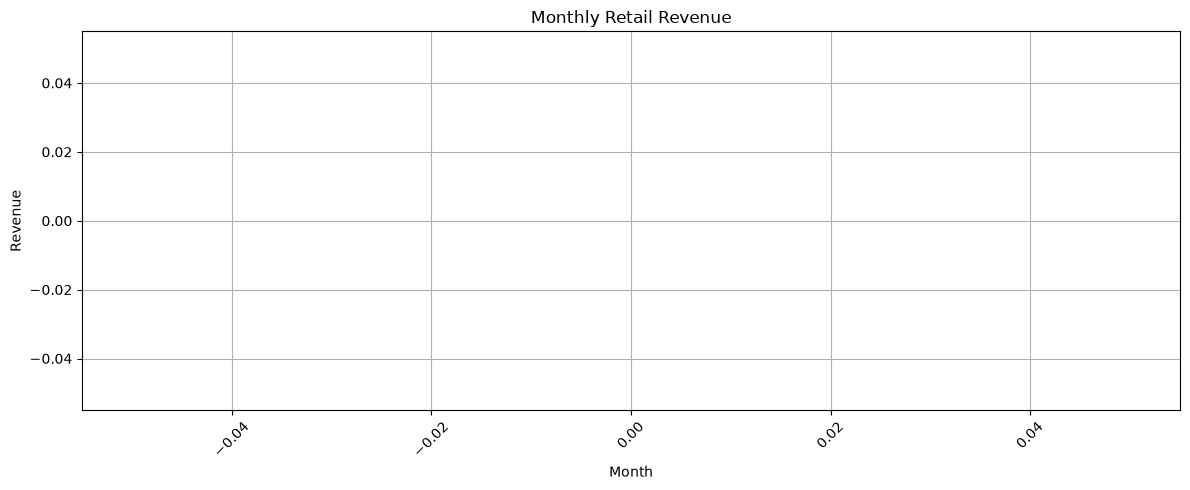

In [23]:
plt.figure(figsize=(12, 5))
plt.plot(
monthly_sales["month"],
monthly_sales["revenue"],
marker="o")
plt.title("Monthly Retail Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()